In [4]:
import tensorflow as tf
print("GPU Available:", tf.config.list_physical_devices('GPU'))

GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Use the dataset ZIP already uploaded through Colab's Files tab.
from pathlib import Path
import zipfile

zip_path = Path("/content/archive.zip")
if not zip_path.is_file():
    raise FileNotFoundError(
        f"Dataset ZIP not found: {zip_path}. "
        "Upload archive.zip through Colab's Files tab, or update zip_path "
        "to the file's location (right-click the file and select Copy path)."
    )

extract_dir = Path("/content/gtsrb_data")
extract_dir.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(zip_path, "r") as archive:
    # Ensure every archive entry stays inside the extraction directory.
    for member in archive.infolist():
        target = (extract_dir / member.filename).resolve()
        if not target.is_relative_to(extract_dir.resolve()):
            raise ValueError(f"Unsafe path in ZIP: {member.filename}")
    archive.extractall(extract_dir)

# Support ZIPs with the dataset at the root or inside a wrapper folder.
candidates = [extract_dir] + sorted(
    {path.parent for path in extract_dir.rglob("Test.csv")}
)
dataset_roots = [
    path for path in candidates
    if (path / "Train").is_dir()
    and (path / "Test").is_dir()
    and (path / "Test.csv").is_file()
]
dataset_roots = list(dict.fromkeys(dataset_roots))
if len(dataset_roots) != 1:
    raise ValueError(
        "Expected one GTSRB dataset containing Train/, Test/, and Test.csv. "
        f"Found {len(dataset_roots)} matching folders under {extract_dir}. "
        "Check the ZIP contents."
    )

data_dir = str(dataset_roots[0])
print(f"Dataset ready: {data_dir}")


In [6]:
import numpy as np
import pandas as pd
import os
import cv2
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D, Dense, Flatten, Dropout
from sklearn.metrics import accuracy_score, classification_report

In [7]:
# data_dir is set by the dataset ZIP upload cell above.
train_path = os.path.join(data_dir, "Train")
NUM_CLASSES = 43
IMG_SIZE = 32

images = []
labels = []

for class_id in range(NUM_CLASSES):
    class_path = os.path.join(train_path, str(class_id))
    for img_name in os.listdir(class_path):
        try:
            img_path = os.path.join(class_path, img_name)
            image = cv2.imread(img_path)
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
            images.append(image)
            labels.append(class_id)
        except Exception as e:
            print(f"Error loading {img_name}: {e}")

images = np.array(images)
labels = np.array(labels)

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: (39209, 32, 32, 3)
Labels shape: (39209,)


In [8]:
images = images / 255.0

X_train, X_val, y_train, y_val = train_test_split(
    images, labels, test_size=0.2, random_state=42, stratify=labels
)

y_train_cat = to_categorical(y_train, NUM_CLASSES)
y_val_cat = to_categorical(y_val, NUM_CLASSES)

print("Train:", X_train.shape, "Val:", X_val.shape)

Train: (31367, 32, 32, 3) Val: (7842, 32, 32, 3)


In [9]:
model = Sequential([
    Conv2D(32, (5,5), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    Conv2D(32, (5,5), activation='relu'),
    MaxPool2D(pool_size=(2,2)),
    Dropout(0.25),

    Conv2D(64, (3,3), activation='relu'),
    Conv2D(64, (3,3), activation='relu'),
    MaxPool2D(pool_size=(2,2)),
    Dropout(0.25),

    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(NUM_CLASSES, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 10, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,939 (1.36 MB)

 Trainable params: 356,939 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(
    X_train, y_train_cat,
    batch_size=64,
    epochs=20,
    validation_data=(X_val, y_val_cat)
)

Epoch 1/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.6078 - loss: 1.4072 - val_accuracy: 0.9564 - val_loss: 0.1969
Epoch 2/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9282 - loss: 0.2382 - val_accuracy: 0.9843 - val_loss: 0.0666
Epoch 3/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9585 - loss: 0.1350 - val_accuracy: 0.9833 - val_loss: 0.0641
Epoch 4/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9647 - loss: 0.1108 - val_accuracy: 0.9897 - val_loss: 0.0359
Epoch 5/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9729 - loss: 0.0871 - val_accuracy: 0.9923 - val_loss: 0.0266
Epoch 6/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9797 - loss: 0.0686 - val_accuracy: 0.9948 - val_loss: 0.0204
Epoch 7/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9815 - loss: 0.0585 - val_accuracy: 0.9949 - val_loss: 0.0183
Epoch 8/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9823 - loss: 0.0593 - val_accuracy: 

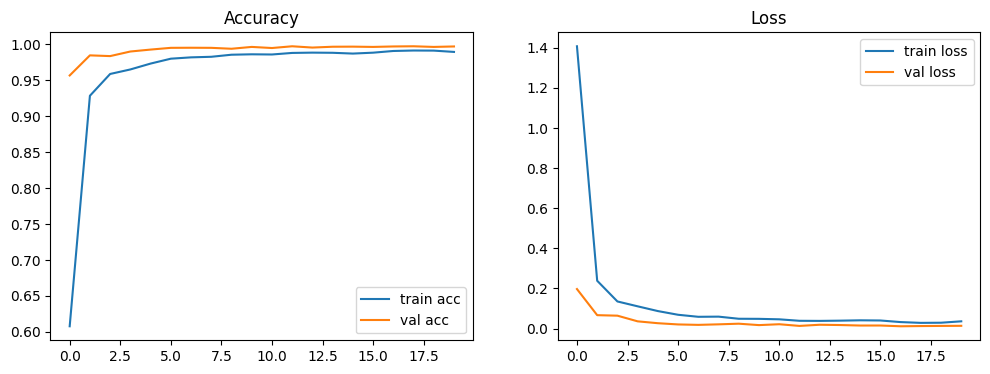

In [11]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.legend()
plt.title('Accuracy')

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.title('Loss')

plt.show()

In [12]:
test_csv = pd.read_csv(os.path.join(data_dir, "Test.csv"))
test_labels = test_csv["ClassId"].values
test_img_paths = test_csv["Path"].values

test_images = []
for img_path in test_img_paths:
    image = cv2.imread(os.path.join(data_dir, img_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
    test_images.append(image)

test_images = np.array(test_images) / 255.0

predictions = model.predict(test_images)
predicted_classes = np.argmax(predictions, axis=1)

print("Test Accuracy:", accuracy_score(test_labels, predicted_classes))
print(classification_report(test_labels, predicted_classes))

395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Test Accuracy: 0.9730799683293745
              precision    recall  f1-score   support

           0       0.98      0.97      0.97        60
           1       0.94      0.99      0.97       720
           2       0.98      0.99      0.99       750
           3       0.96      0.99      0.97       450
           4       0.98      0.98      0.98       660
           5       0.97      0.96      0.97       630
           6       1.00      0.76      0.86       150
           7       0.99      0.99      0.99       450
           8       1.00      0.98      0.99       450
           9       0.97      1.00      0.98       480
          10       1.00      0.99      0.99       660
          11       0.97      0.99      0.98       420
          12       0.99      0.99      0.99       690
          13       1.00      1.00      1.00       720
          14       0.99      1.00      0.99       270
          15       0.98      0.99      0.99       210
      

In [13]:
model.save("traffic_sign_model.h5")

from google.colab import files
files.download("traffic_sign_model.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>